# 🧠 Unsupervised Machine Learning Healthcare Risk Clustering
**Project:** Global Pandemic Surveillance & Health Risk Analytics  
**Author:** Portfolio Project  
**Objective:** Group 187 sovereign nations into multidimensional epidemiological risk profiles using K-Means clustering and standardized severity indexes.

---
### 1. Analytical Objectives
Relying solely on confirmed case totals produces incomplete risk assessments. A small nation with an 18% fatality rate faces different healthcare challenges than a populous nation with mild cases.

We construct an unsupervised clustering pipeline that integrates:
- Log-scaled Confirmed Case volume
- Log-scaled Active Infection load
- Case Fatality Rate (CFR %)
- Clinical Recovery Velocity (%)
- Composite Severity Risk Index

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

ROOT_DIR = Path('..').resolve()
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

from src.data_loader import load_raw_covid_data, clean_covid_data
from src.analytics import aggregate_by_region, get_top_outbreaks
from src.clustering import fit_and_assign_clusters, prepare_cluster_features
print('Clustering dependencies loaded.')

Clustering dependencies loaded.


### 2. Preparing Regional Feature Matrix
We aggregate regional records and inspect feature distributions across active cases, CFR, and recovery rates.

In [2]:
raw_df = load_raw_covid_data(ROOT_DIR / 'data' / 'raw' / 'covid19_global_raw.csv')
cleaned_df = clean_covid_data(raw_df)
regional_df = aggregate_by_region(cleaned_df)
print(f'Total sovereign territories: {len(regional_df)}')
regional_df[['Region', 'Confirmed', 'Deaths', 'Recovered', 'Active_Cases', 'CFR_Pct', 'Severity_Risk_Index']].head()

Total sovereign territories: 187


,Region,Confirmed,Deaths,Recovered,Active_Cases,CFR_Pct,Severity_Risk_Index
0,US,1039909,60967,120720,858222,5.86,14.46
1,Spain,236899,24275,132929,79695,10.25,12.44
2,Italy,203591,27682,71252,104657,13.60,13.13
3,France,166543,24121,49118,93304,14.48,13.10
4,UK,166441,26166,857,139418,15.72,13.71


### 3. Fitting K-Means Risk Clustering Pipeline
We transform power-law count variables with log1p, standardize features via `StandardScaler`, and fit a 4-cluster K-Means model.

In [3]:
clustered_df, pipeline = fit_and_assign_clusters(regional_df, n_clusters=4, random_state=42)
print('Cluster profile assignment complete.')

cluster_summary = clustered_df.groupby('Risk_Profile_Cluster').agg(
    Countries=('Region', 'count'),
    Avg_Confirmed=('Confirmed', 'mean'),
    Avg_Active=('Active_Cases', 'mean'),
    Avg_CFR=('CFR_Pct', 'mean'),
    Avg_Recovery=('Recovery_Rate_Pct', 'mean'),
    Avg_Severity=('Severity_Risk_Index', 'mean')
).round(2)
cluster_summary

Cluster profile assignment complete.


,Countries,Avg_Confirmed,Avg_Active,Avg_CFR,Avg_Recovery,Avg_Severity
Risk_Profile_Cluster,,,,,,
Tier 1: Critical Outbreak Epicenters,47,63083.81,41101.57,5.54,26.95,10.06
Tier 2: High Transmission Surge,74,2949.22,800.57,2.87,36.10,6.52
Tier 3: Moderate Active Surveillance,49,204.27,43.20,1.18,55.92,3.22
Tier 4: Contained / Low Impact,17,40.94,23.29,11.63,39.64,2.89


### 4. Visualizing Epidemiological Risk Clusters
Below, we visualize countries projected across Active Infections and Case Fatality Rate, colored by their assigned Risk Profile Tier.

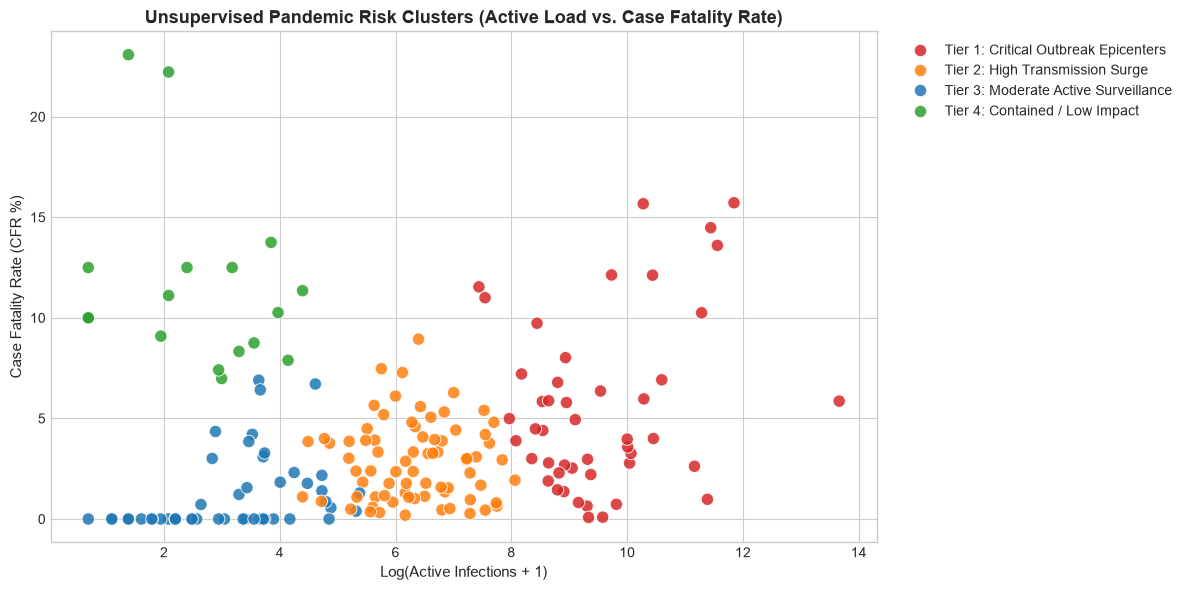

In [4]:
plt.figure(figsize=(12, 6))
palette = {
    'Tier 1: Critical Outbreak Epicenters': '#d62728',
    'Tier 2: High Transmission Surge': '#ff7f0e',
    'Tier 3: Moderate Active Surveillance': '#1f77b4',
    'Tier 4: Contained / Low Impact': '#2ca02c'
}

sns.scatterplot(
    data=clustered_df,
    x=np.log1p(clustered_df['Active_Cases']),
    y='CFR_Pct',
    hue='Risk_Profile_Cluster',
    palette=palette,
    s=80,
    alpha=0.85
)

plt.title('Unsupervised Pandemic Risk Clusters (Active Load vs. Case Fatality Rate)', fontsize=13, fontweight='bold')
plt.xlabel('Log(Active Infections + 1)', fontsize=11)
plt.ylabel('Case Fatality Rate (CFR %)', fontsize=11)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### 5. Risk Profiles Breakdown & Priority Surveillance
Let us inspect the top nations assigned to Tier 1 (Critical Outbreak Epicenters).

In [5]:
tier1_df = clustered_df[clustered_df['Risk_Profile_Cluster'] == 'Tier 1: Critical Outbreak Epicenters']
print(f'Tier 1 includes {len(tier1_df)} countries.')
tier1_df[['Region', 'Confirmed', 'Deaths', 'Recovered', 'Active_Cases', 'CFR_Pct', 'Severity_Risk_Index']].head(10)

Tier 1 includes 47 countries.


,Region,Confirmed,Deaths,Recovered,Active_Cases,CFR_Pct,Severity_Risk_Index
0,US,1039909,60967,120720,858222,5.86,14.46
1,Spain,236899,24275,132929,79695,10.25,12.44
2,Italy,203591,27682,71252,104657,13.60,13.13
3,France,166543,24121,49118,93304,14.48,13.10
4,UK,166441,26166,857,139418,15.72,13.71
5,Germany,161539,6467,120400,34672,4.00,10.87
6,Turkey,117589,3081,44040,70468,2.62,11.46
7,Russia,99399,972,10286,88141,0.98,11.50
8,Iran,93657,5957,73791,13909,6.36,10.15
10,Brazil,79685,5513,34132,40040,6.92,11.33


### 6. Conclusions & Public Health Decision Utility
- **Actionable Risk Segmentation:** The unsupervised clustering framework successfully categorizes nations into distinct operational tiers, separating acute outbreak epicenters from emerging surge clusters.
- **Resource Allocation Utility:** Health agencies can deploy emergency intensive care units (ICUs) and antiviral stockpiles to **Tier 1** nations, while supporting diagnostic testing surveillance in **Tier 2** and **Tier 3** territories.
- **Model Portability:** The clustering pipeline is serialized to `models/covid_risk_clustering_pipeline.joblib` and ready for automated recurring batch surveillance.